# 04 · Crime trends and neighborhood profile (run on LinuxONE)

For city government and urban analysts: how crime that affects residents is trending in each neighborhood, and where it coincides with the profile of abandoned housing from notebook 03.

- **Crime groups by who they affect:** residential, domestic violence, vehicle, commercial. Police activity (arrests on warrants, weapons seized) and non-crime records are excluded, so malls and busy avenues do not make residential areas look dangerous.
- **Rates per km²,** not per resident, so low-population commercial areas are not inflated.
- **Trend per neighborhood (AGEB):** Jan to Sep 2026 against the same months of 2025. Only 2025 and 2026 share the same category names (see section 2), and comparing the same months avoids seasonality.
- **Domestic violence is its own group:** its reports drop by about half from January 2026 in one step, which looks like a recording change, so it is shown but does not drive the neighborhood trend.
- **Profile:** risk, reasons, crime trend and access, for any block or neighborhood.

Data: `data/crimes_by_ageb.csv` (IMIP crime records tagged with their AGEB by `scripts/prepare_features.py`), `data/ageb_features.csv`, `results/block_risk.csv` (notebook 03). Only pandas, numpy and matplotlib.

In [1]:
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

cr = pd.read_csv("../data/crimes_by_ageb.csv", dtype={"ageb": str})
ageb = pd.read_csv("../data/ageb_features.csv", dtype={"CVEGEO": str})
risk = pd.read_csv("../results/block_risk.csv", dtype={"CVEGEO": str, "AGEB_KEY": str})
LAST_MONTH = 9  # IMIP 2026 data runs through September
bad = (cr.year == 2026) & (cr.month > LAST_MONTH)
cr = cr[~bad & cr.month.between(1, 12)]
print(len(cr), "crime records |", bad.sum(), "dropped (2026 dates after September)")

30141 crime records | 3 dropped (2026 dates after September)


## 1. Clean and group crime categories
IMIP category names come with broken accents (`HABITACIàN`, `DA¥OS`); they are normalized first. Groups are assigned by keyword, in order; anything unmatched is residential. Review the table below: ambiguous cases such as `ROBO SIN VIOLENCIA` (no place given) are counted as residential.

In [2]:
def clean(s):
    s = str(s)
    for bad_char, good in {"à": "O", "¥": "Ñ", "Ö": "I"}.items():  # mojibake seen in the IMIP data
        s = s.replace(bad_char, good)
    s = unicodedata.normalize("NFKD", s.upper()).encode("ascii", "ignore").decode()
    return " ".join(s.split())

GROUP_RULES = [
    ("police activity", ["DET. ORDEN", "PORTAR OBJETOS", "ARMAS DECOMISADAS", "CARTUCHOS", "POSESION", "PORTACION", "CONTRA LA LEY FED",
                         "RECUPERADO", "DESOBEDIENCIA", "PLACAS SOBREPUESTAS", "SERIE ALTERADA", "DOCUMENTOS ALTERADOS",
                         "USURPACION", "FALSIF", "PROMOCION DE CONDUCTAS", "TRAFICO DE INDOCUMENTADOS", "FUERO FEDERAL"]),
    ("other", ["INTENTO DE SUICIDIO", "OSAMENTA", "INHUMACION", "MALTRATO ANIMAL", "ABORTO", "OTRO DELITOS", "ROBO OTROS"]),
    ("vehicle", ["ROBO DE VEHICULO", "MOTOCICLETA", "AUTOPARTES"]),
    ("domestic violence", ["VIOLENCIA FAMILIAR"]),
    ("commercial", ["CASA COMERCIAL", "ROBO A NEGOCIO", "ROBO A ESCUELA", "FRAUDE", "EXTORSION", "ABUSO CONFIANZA", "HIDROCARBUROS",
                    "ELECTRICIDAD", "MEDIDOR"]),
]

def group_of(cat):
    for group, keys in GROUP_RULES:
        if any(k in cat for k in keys):
            return group
    return "residential"

cr["category"] = cr.category.map(clean)
cr["group"] = cr.category.map(group_of)
mapping = cr.groupby(["group", "category"]).size().rename("records").reset_index()
print(cr.group.value_counts().to_string())
mapping.sort_values(["group", "records"], ascending=[True, False]).groupby("group").head(8)

group
residential          10880
police activity       8427
commercial            4725
domestic violence     2732
vehicle               2414
other                  963


,group,category,records
11,commercial,ROBO A NEGOCIO,1667
6,commercial,ROBO A CASA COMERCIAL CON VIOLENCIA,1357
9,commercial,ROBO A CASA COMERCIAL SIN VIOLENCIA,1342
10,commercial,ROBO A ESCUELA,89
3,commercial,FRAUDE,86
8,commercial,ROBO A CASA COMERCIAL SIN VIOLE*,57
2,commercial,EXTORSION,45
0,commercial,ABUSO CONFIANZA,44
14,domestic violence,VIOLENCIA FAMILIAR,2732
21,other,ROBO OTROS,839


## 2. City-wide trend by group
IMIP changed its category names between years: `ROBO A NEGOCIO` exists until 2024 and becomes `ROBO A CASA COMERCIAL` in 2025; `VIOLENCIA FAMILIAR` and `ROBO DE VEHICULO` do not appear in 2020. Group comparisons are therefore only valid between **2025 and 2026**. Domestic violence drops by about half from January 2026 in one step, which looks like a recording change.

Jan to Sep of each year:


year,2025,2026,change_2026_vs_2025
group,,,
commercial,1022,980,-0.041
domestic violence,1608,873,-0.457
other,61,44,-0.279
police activity,1998,2252,0.127
residential,2747,1911,-0.304
vehicle,877,648,-0.261


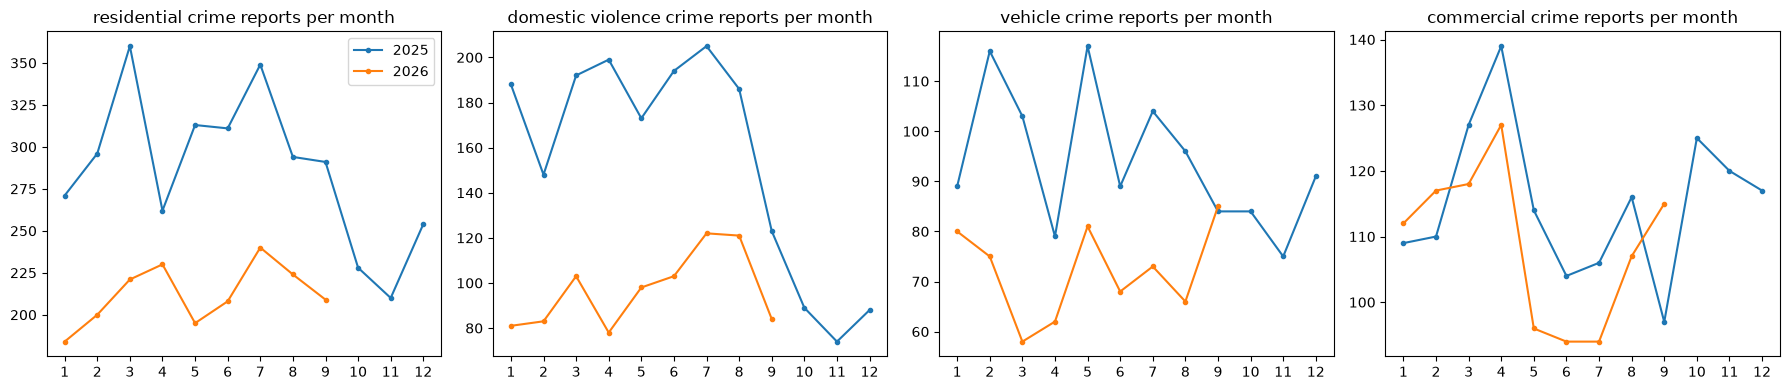

In [3]:
GROUPS = ["residential", "domestic violence", "vehicle", "commercial"]
monthly = cr[cr.group.isin(GROUPS)].groupby(["group", "year", "month"]).size()
fig, ax = plt.subplots(1, 4, figsize=(18, 4), sharey=False)
for a, g in zip(ax, GROUPS):
    for y in [2025, 2026]:
        s = monthly.get(g, pd.Series(dtype=float))
        s = s[s.index.get_level_values(0) == y] if len(s) else s
        a.plot(s.index.get_level_values(1), s.values, marker="o", ms=3, label=str(y))
    a.set_title(f"{g} crime reports per month")
    a.set_xticks(range(1, 13))
ax[0].legend()
plt.tight_layout()

ytd = cr[(cr.month <= LAST_MONTH) & (cr.year >= 2025)].pivot_table(index="group", columns="year", aggfunc="size", fill_value=0)
ytd["change_2026_vs_2025"] = (ytd[2026] / ytd[2025] - 1).round(3)
print("Jan to Sep of each year:")
ytd

## 3. Residential crime trend per neighborhood
Residential crime (without domestic violence) Jan to Sep 2026 vs Jan to Sep 2025, per km². A neighborhood is **rising** if it grew at least 25% and by at least 5 reports, **falling** if it dropped at least 20%. Commercial and vehicle crime are kept as context. A neighborhood is tagged **commercial / transit** when most of its non-police crime is commercial or vehicle (malls, avenues).

In [4]:
ytd_cr = cr[(cr.month <= LAST_MONTH) & cr.ageb.notna()]
counts = ytd_cr.pivot_table(index="ageb", columns=["group", "year"], aggfunc="size", fill_value=0)

t = ageb.set_index("CVEGEO")[["POBTOT", "TVIVPAR", "VIVPAR_DES", "pct_vacant", "area_km2", "lon", "lat",
                              "km_maquila", "km_brt", "km_health", "km_center", "year_urbanized"]].copy()
for g in ["residential", "domestic violence", "vehicle", "commercial"]:
    for y in [2025, 2026]:
        t[f"{g}_{y}"] = counts.get((g, y), pd.Series(dtype=float)).reindex(t.index).fillna(0)
t["residential_per_km2_2026"] = t.residential_2026 / t.area_km2
t["residential_change"] = (t.residential_2026 - t.residential_2025) / t.residential_2025.where(t.residential_2025 > 0)
diff = t.residential_2026 - t.residential_2025
t["residential_trend"] = np.select(
    [(t.residential_change >= 0.25) & (diff >= 5), t.residential_change <= -0.20], ["rising", "falling"], "stable")

non_police_2026 = t[["residential_2026", "vehicle_2026", "commercial_2026"]].sum(axis=1)
t["commercial_transit_zone"] = ((t.vehicle_2026 + t.commercial_2026) / non_police_2026.where(non_police_2026 > 0) >= 0.5) & (non_police_2026 >= 20)

top_colonia = cr.dropna(subset=["ageb"]).groupby("ageb").colonia.agg(lambda s: s.mode().iat[0] if len(s.mode()) else "")
t["colonia"] = top_colonia.reindex(t.index).fillna("")

blocks = risk.groupby("AGEB_KEY").agg(blocks=("CVEGEO", "size"), share_high_risk=("risk_level", lambda s: (s == "high").mean()),
                                       mean_risk_score=("risk_score", "mean"))
t = t.join(blocks)
print(t.residential_trend.value_counts().to_string())
print("commercial / transit zones:", int(t.commercial_transit_zone.sum()))
t[t.commercial_transit_zone].nlargest(8, "commercial_2026")[["colonia", "commercial_2026", "vehicle_2026", "residential_2026", "POBTOT"]]

residential_trend
falling    292
stable     266
rising       9
commercial / transit zones: 9


,colonia,commercial_2026,vehicle_2026,residential_2026,POBTOT
CVEGEO,,,,,
0803700012450,NUEVO HIPODROMO,33.0,7.0,14.0,1801
0803700017057,PARAJES DEL SUR FRACCIONAMIENTO,15.0,7.0,7.0,7059
0803700016862,PRADERAS DE LOS ALAMOS,14.0,19.0,7.0,5991
0803700012376,DIVISION DEL NORTE COL.,14.0,1.0,9.0,1803
080370001795A,PARAJES DE SAN ISIDRO,12.0,8.0,12.0,8002
0803700011611,INDUSTRIAL,11.0,1.0,8.0,2413
0803700016716,FRIDA KHALO,11.0,4.0,15.0,6709
0803700015900,TIERRA NUEVA I,9.0,2.0,11.0,6885


## 4. Where vacancy profile and residential crime coincide
Priority list for the city: neighborhoods where at least 30% of blocks have a high abandonment profile (notebook 03), residential crime is **not falling** (rising or stable vs 2025), and its density is above the city median. Residential crime fell city-wide in 2026, so "rising" alone would leave almost no neighborhoods.

In [5]:
median_density = t.residential_per_km2_2026.median()
priority = t[(t.share_high_risk >= 0.30) & (t.residential_trend != "falling")
             & (t.residential_per_km2_2026 >= median_density)].copy()
priority = priority.sort_values(["share_high_risk", "residential_change"], ascending=False)
print(len(priority), "priority neighborhoods")
priority[["colonia", "share_high_risk", "pct_vacant", "VIVPAR_DES", "residential_2025", "residential_2026",
          "residential_change", "residential_trend", "residential_per_km2_2026", "km_center"]].round(2).head(15)

36 priority neighborhoods


,colonia,share_high_risk,pct_vacant,VIVPAR_DES,residential_2025,residential_2026,residential_change,residential_trend,residential_per_km2_2026,km_center
CVEGEO,,,,,,,,,,
0803700011005,BARRIO ALTO,1.00,30.61,60.0,3.0,5.0,0.67,stable,38.78,0.45
0803700010859,EL BARREAL,1.00,24.17,109.0,3.0,3.0,0.00,stable,13.77,1.09
080370001069A,PARTIDO ROMERO,1.00,29.59,153.0,9.0,8.0,-0.11,stable,30.15,0.79
0803700010825,BELLAVISTA,0.95,33.92,116.0,4.0,4.0,0.00,stable,26.85,0.50
0803700018106,JARDINES DE ROMA,0.93,74.67,737.0,2.0,4.0,1.00,stable,9.75,26.01
0803700013694,CHAVEÑA,0.93,27.08,65.0,2.0,2.0,0.00,stable,6.42,1.90
0803700011081,BARRIO ALTO,0.88,24.90,121.0,1.0,2.0,1.00,stable,16.85,0.84
0803700018479,MISIONES DE CREEL,0.88,27.82,79.0,0.0,2.0,NaN,stable,10.68,23.90
0803700010810,BELLAVISTA,0.86,26.99,132.0,2.0,2.0,0.00,stable,11.70,0.88


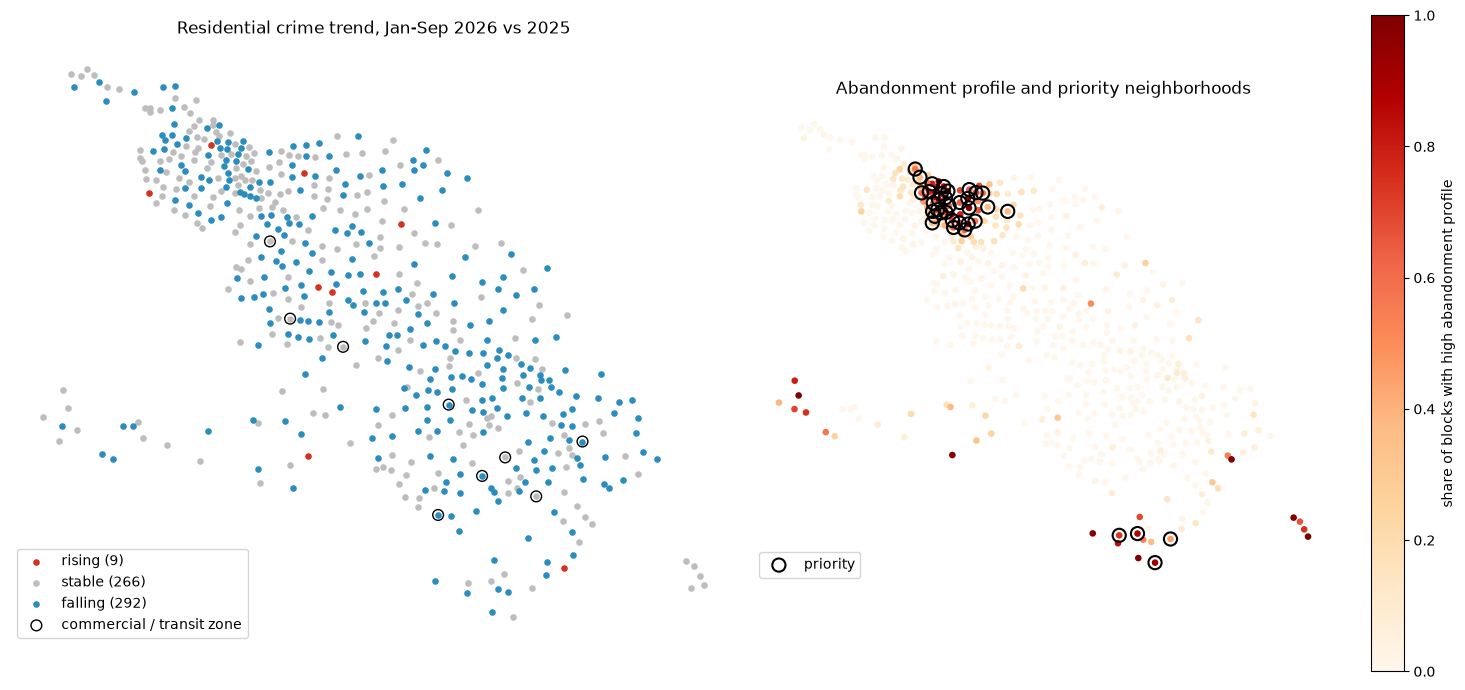

In [6]:
colors = {"rising": "#d7301f", "stable": "#bdbdbd", "falling": "#2b8cbe"}
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
for k, c in colors.items():
    s = t[t.residential_trend == k]
    ax[0].scatter(s.lon, s.lat, s=14, c=c, label=f"{k} ({len(s)})")
ax[0].scatter(t[t.commercial_transit_zone].lon, t[t.commercial_transit_zone].lat, s=60, facecolors="none",
              edgecolors="black", label="commercial / transit zone")
ax[0].set_title("Residential crime trend, Jan-Sep 2026 vs 2025")
ax[0].legend(loc="lower left")
s = ax[1].scatter(t.lon, t.lat, s=14, c=t.share_high_risk, cmap="OrRd")
ax[1].scatter(priority.lon, priority.lat, s=90, facecolors="none", edgecolors="black", linewidths=1.5, label="priority")
fig.colorbar(s, ax=ax[1], label="share of blocks with high abandonment profile")
ax[1].set_title("Abandonment profile and priority neighborhoods")
ax[1].legend(loc="lower left")
for a in ax:
    a.set_aspect("equal")
    a.set_axis_off()
plt.tight_layout()

## 5. Neighborhood profile
`profile(key)` takes a block key (16 characters), an AGEB key (13 characters) or part of a colonia name.

In [7]:
def top_types(ageb_key, group, n=3):
    s = ytd_cr[(ytd_cr.ageb == ageb_key) & (ytd_cr.year == 2026) & (ytd_cr.group == group)].category.value_counts()
    return ", ".join(f"{c.lower()} ({v})" for c, v in s.head(n).items()) or "none"

def profile(key):
    key = str(key)
    block = None
    if len(key) == 16 and key in set(risk.CVEGEO):
        block = risk.set_index("CVEGEO").loc[key]
        ageb_key = block.AGEB_KEY
    elif key in t.index:
        ageb_key = key
    else:
        hits = t[t.colonia.str.contains(key.upper(), na=False)]
        if hits.empty:
            return print("not found:", key)
        ageb_key = hits.VIVPAR_DES.idxmax()
    n = t.loc[ageb_key]
    lines = [f"Neighborhood {ageb_key} ({n.colonia.title() or 'no name'})"]
    if block is not None:
        lines.append(f"  Block {key}: {block.risk_level.upper()} abandonment profile (score {block.risk_score:.1f}, actual {block.target_pct_vacant:.1f}% vacant)")
        lines += [f"    - {r}" for r in [block.reason_1, block.reason_2, block.reason_3] if isinstance(r, str) and r]
    lines.append(f"  Vacancy 2020: {n.pct_vacant:.1f}% ({int(n.VIVPAR_DES)} homes) | blocks with high profile: {n.share_high_risk:.0%}")
    chg = "n/a" if pd.isna(n.residential_change) else f"{n.residential_change:+.0%}"
    lines.append(f"  Residential crime Jan-Sep 2026: {int(n.residential_2026)} reports ({n.residential_per_km2_2026:.1f} per km2), "
                 f"{n.residential_trend} vs 2025 ({chg}); top: {top_types(ageb_key, 'residential')}")
    lines.append(f"  Domestic violence Jan-Sep 2026: {int(n['domestic violence_2026'])} reports (2025: {int(n['domestic violence_2025'])}; recording changed in 2026)")
    lines.append(f"  Vehicle crime: {int(n.vehicle_2026)} | commercial crime: {int(n.commercial_2026)}"
                 + (" | commercial / transit zone: these reflect visitors, not residents" if n.commercial_transit_zone else ""))
    lines.append(f"  Access: maquila {n.km_maquila:.1f} km | BRT {n.km_brt:.1f} km | health unit {n.km_health:.1f} km | center {n.km_center:.1f} km")
    lines.append("  2030 outlook: pending (notebook 03b)")
    print("\n".join(lines))

profile(risk[risk.risk_level == "high"].nlargest(1, "risk_score").CVEGEO.iat[0])
print()
profile(t[t.commercial_transit_zone].commercial_2026.idxmax())

Neighborhood 0803700018286 (Senderos De Oriente)
  Block 0803700018286022: HIGH abandonment profile (score 69.2, actual 41.7% vacant)
    - km to city center: 25.3 (city median 9.6, +12.9 pts)
    - % homes with car: not reported (city median 65.4, +7.6 pts)
    - km to BRT station: 7.5 (city median 1.7, +6.2 pts)
  Vacancy 2020: 36.7% (171 homes) | blocks with high profile: 100%
  Residential crime Jan-Sep 2026: 2 reports (3.9 per km2), falling vs 2025 (-67%); top: omision de cuidados (1), privacion de la libertad (1)
  Domestic violence Jan-Sep 2026: 3 reports (2025: 1; recording changed in 2026)
  Vehicle crime: 0 | commercial crime: 0
  Access: maquila 2.4 km | BRT 7.2 km | health unit 1.5 km | center 25.4 km
  2030 outlook: pending (notebook 03b)



Neighborhood 0803700012450 (Nuevo Hipodromo)
  Vacancy 2020: 8.3% (44 homes) | blocks with high profile: 9%
  Residential crime Jan-Sep 2026: 14 reports (13.3 per km2), stable vs 2025 (-12%); top: danos (4), lesiones arma blanca (2), robo sin violencia (2)
  Domestic violence Jan-Sep 2026: 1 reports (2025: 1; recording changed in 2026)
  Vehicle crime: 7 | commercial crime: 33 | commercial / transit zone: these reflect visitors, not residents
  Access: maquila 0.2 km | BRT 0.8 km | health unit 0.6 km | center 10.2 km
  2030 outlook: pending (notebook 03b)


## 6. Save

In [8]:
cols = ["colonia", "POBTOT", "pct_vacant", "VIVPAR_DES", "share_high_risk", "mean_risk_score", "area_km2",
        "residential_2025", "residential_2026", "residential_per_km2_2026", "residential_change", "residential_trend",
        "domestic violence_2025", "domestic violence_2026", "vehicle_2026", "commercial_2026", "commercial_transit_zone", "lon", "lat"]
t[cols].round(3).rename_axis("ageb").to_csv("../results/crime_trends_ageb.csv")
mapping.to_csv("../results/crime_category_groups.csv", index=False)
print("saved results/crime_trends_ageb.csv and results/crime_category_groups.csv")

saved results/crime_trends_ageb.csv and results/crime_category_groups.csv
